<a href="https://colab.research.google.com/github/tousif47/Geostormcaster/blob/main/05_model_a_t3h_1m.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 05 — Model A: t+3h storm forecast, 1-minute data (G1+)

Task: detect geomagnetic storms (Kp >= 5, NOAA G1 threshold) in the next
3-hour block, from 24h windows of 5-min bins built at 1-minute resolution.

- Inputs: 288 x 6 physics-informed features (coupling functions computed
  on 1-min values preserve shock/southward-turning structure that hourly
  averaging erases)
- Formulation: binary (storm vs. non-storm), sigmoid output, threshold
  swept on validation
- Selection metric: storm F1 on validation; test set used once, at the end
- Comparison: persistence baseline on the identical split; the reference
  band is research-grade 3h models (storm F1 ~ 0.55)

In [14]:
import numpy as np
import json
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import confusion_matrix, classification_report, f1_score

tf.keras.utils.set_random_seed(42)

OUT_DIR = '/content/drive/MyDrive/temp'
CSV     = f'{OUT_DIR}/omni_clean.csv'

D = np.load(f'{OUT_DIR}/windows_a1m.npz')
XA = {k: D[k] for k in D.files}
print({k: v.shape for k, v in XA.items()})

# storm = G1+ (Kp >= 5), applied on the exact Kp labels stored in the npz
yb_tr = (XA['ytr'] >= 5).astype(np.float32)
yb_va = (XA['yva'] >= 5).astype(np.float32)
CLASS_WEIGHT = {0: 1.0, 1: 8.0}
print(f'train: storm share = {yb_tr.mean():.3f}')

{'Xtr': (121277, 288, 6), 'Xva': (62258, 288, 6), 'Xte': (59262, 288, 6), 'ytr': (121277,), 'yva': (62258,), 'yte': (59262,), 'ttr': (121277,), 'tva': (62258,), 'tte': (59262,)}
train: storm share = 0.034


## Baselines (validation)

1. **Climatology** — always predict non-storm: the accuracy trap made
   visible with real numbers.
2. **Persistence** — predict the current block's class ("next = same").
   At 3h lead this is a strong baseline; the trained model must beat it.

In [15]:
df = pd.read_csv(CSV, parse_dates=['timestamp']).set_index('timestamp')

def eval_bin(y_true, y_pred, name):
    print(f'--- {name} ---')
    print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
    print(classification_report(y_true, y_pred,
          target_names=['non-storm', 'storm'], digits=3, zero_division=0))
    return f1_score(y_true, y_pred)

f1_climo = eval_bin(yb_va, np.zeros_like(yb_va), 'Climatology (always non-storm)')

cur_kp = df['kp'].reindex(XA['tva']).clip(upper=9).values
f1_persist = eval_bin(yb_va, (cur_kp >= 5).astype(int), 'Persistence')

--- Climatology (always non-storm) ---
[[60889     0]
 [ 1369     0]]
              precision    recall  f1-score   support

   non-storm      0.978     1.000     0.989     60889
       storm      0.000     0.000     0.000      1369

    accuracy                          0.978     62258
   macro avg      0.489     0.500     0.494     62258
weighted avg      0.957     0.978     0.967     62258

--- Persistence ---
[[60189   700]
 [  700   669]]
              precision    recall  f1-score   support

   non-storm      0.989     0.989     0.989     60889
       storm      0.489     0.489     0.489      1369

    accuracy                          0.978     62258
   macro avg      0.739     0.739     0.739     62258
weighted avg      0.978     0.978     0.978     62258



## Candidates

Three architectures, identical training recipe — only the architecture
differs. All use a binary sigmoid head.

1. **MLP on window statistics** — each 288x6 window collapsed to 18 numbers
   (mean/std/min per feature)
2. **1D-CNN** — learns local temporal motifs in the raw window
3. **GRU** — recurrent memory over the full 24h at 5-min resolution

In [16]:
def window_stats(X):
    return np.concatenate([X.mean(axis=1), X.std(axis=1), X.min(axis=1)], axis=1)

S = {k: (window_stats(v) if k.startswith('X') else v) for k, v in XA.items()}

def make_mlp():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(18,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def make_cnn():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(288, 6)),
        tf.keras.layers.Conv1D(32, 5, activation='relu'),
        tf.keras.layers.Conv1D(64, 5, activation='relu'),
        tf.keras.layers.GlobalAveragePooling1D(),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def make_gru():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(288, 6)),
        tf.keras.layers.GRU(16),
        tf.keras.layers.Dense(1, activation='sigmoid')])

def train_bin(make_model, Xtr, Xva, tag, epochs=25, patience=4):
    m = make_model()
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    m.fit(Xtr, yb_tr,
          validation_data=(Xva, yb_va),
          epochs=epochs, batch_size=256, class_weight=CLASS_WEIGHT,
          callbacks=[tf.keras.callbacks.EarlyStopping(
              patience=patience, restore_best_weights=True)],
          verbose=1)
    m.save(f'{OUT_DIR}/model_a1m_{tag}.keras')
    return m

## Training

Runtime note: sequences are 12x longer than the hourly track (288 steps vs
24), so the GRU is roughly an order of magnitude slower per epoch — tens
of minutes total is normal, longer on CPU-only sessions.

In [17]:
m_mlp = train_bin(make_mlp, S['Xtr'], S['Xva'], 'mlp')
m_cnn = train_bin(make_cnn, XA['Xtr'], XA['Xva'], 'cnn')
m_gru = train_bin(make_gru, XA['Xtr'], XA['Xva'], 'gru')

candidates = {'MLP': (m_mlp, S['Xva']),
              '1D-CNN': (m_cnn, XA['Xva']),
              'GRU': (m_gru, XA['Xva'])}

Epoch 1/25
474/474 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.9058 - loss: 0.4666 - val_accuracy: 0.9324 - val_loss: 0.1695
Epoch 2/25
474/474 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9133 - loss: 0.4120 - val_accuracy: 0.9368 - val_loss: 0.1591
Epoch 3/25
474/474 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9182 - loss: 0.4049 - val_accuracy: 0.9388 - val_loss: 0.1527
Epoch 4/25
474/474 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9206 - loss: 0.3997 - val_accuracy: 0.9364 - val_loss: 0.1571
Epoch 5/25
474/474 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9230 - loss: 0.3951 - val_accuracy: 0.9369 - val_loss: 0.1571
Epoch 6/25
474/474 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9233 - loss: 0.3918 - val_accuracy: 0.9380 - val_loss: 0.1540
Epoch 7/25
474/474 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9237 - loss: 0.3895 - val_accuracy: 0.9362 - val_loss: 0.1558
Epoch 1/25
474/474 ━━━━━━━━━━━━━━━━━━━━ 106s 221ms/step - accuracy: 0.9111 - loss: 0.4639 - val_accuracy

## Threshold sweep (validation)

Predict storm when P(storm) > tau, swept on validation. The chosen tau
becomes a fixed constant of the deployed model, like the normalization
constants.

MLP      best tau=0.61  val storm F1=0.331
1D-CNN   best tau=0.47  val storm F1=0.303
GRU      best tau=0.69  val storm F1=0.443


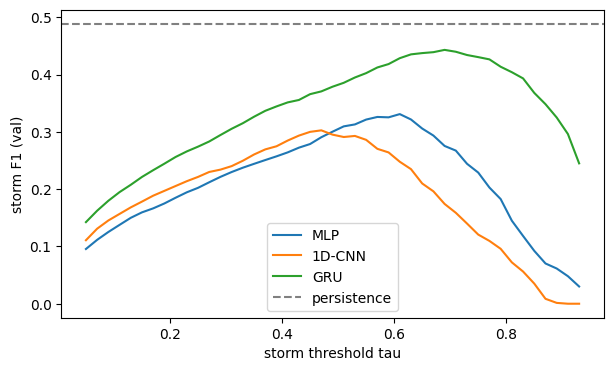

In [18]:
taus = np.arange(0.05, 0.95, 0.02)
swept = {}

plt.figure(figsize=(7, 4))
for name, (m, Xv) in candidates.items():
    p = m.predict(Xv, verbose=0).squeeze()
    f1s = [f1_score(yb_va, (p > t).astype(int)) for t in taus]
    best = int(np.argmax(f1s))
    swept[name] = (float(taus[best]), float(f1s[best]))
    print(f'{name:8s} best tau={taus[best]:.2f}  val storm F1={f1s[best]:.3f}')
    plt.plot(taus, f1s, label=name)

plt.axhline(f1_persist, color='gray', linestyle='--', label='persistence')
plt.xlabel('storm threshold tau'); plt.ylabel('storm F1 (val)')
plt.legend(); plt.show()

## Winner → test set, once

The validation-selected model and tau are evaluated a single time on the
2019+ test split, side-by-side with persistence on the identical split.
This is the only point the test set is used. Everything is written to
model_a1m_results.json.

In [19]:
winner_name = max(swept, key=lambda n: swept[n][1])
best_tau, best_f1 = swept[winner_name]
print(f'winner: {winner_name} (tau={best_tau:.2f}, val storm F1={best_f1:.3f})')

w_model = candidates[winner_name][0]
if winner_name == 'MLP':
    w_Xte = S['Xte']
else:
    w_Xte = XA['Xte']

p_te = w_model.predict(w_Xte, verbose=0).squeeze()
pred_te = (p_te > best_tau).astype(int)
yb_te = (XA['yte'] >= 5).astype(int)
f1_test = eval_bin(yb_te, pred_te, f'{winner_name} (tau={best_tau:.2f}) on TEST')

cur_kp_te = df['kp'].reindex(XA['tte']).clip(upper=9).values
f1_persist_te = eval_bin(yb_te, (cur_kp_te >= 5).astype(int),
                         'Persistence on TEST')

print('\n===== FINAL COMPARISON (test split) =====')
print(f'{winner_name} (tau={best_tau:.2f})  storm F1 = {f1_test:.3f}')
print(f'Persistence                  storm F1 = {f1_persist_te:.3f}')

summary = {
    'task': 'model_a_t3h_storm_binary_g1_1min',
    'resolution': '1-min data, 5-min bins, 288-step windows',
    'storm_definition': 'Kp >= 5 (G1+)',
    'features': ['bz_gsm', 'speed', 'density', 'newell', 'rect_v', 'pressure'],
    'winner': winner_name,
    'best_tau': best_tau,
    'val_storm_f1': {n: v[1] for n, v in swept.items()},
    'val_storm_f1_baselines': {'climatology': float(f1_climo),
                               'persistence': float(f1_persist)},
    'test_storm_f1': float(f1_test),
    'test_storm_f1_persistence': float(f1_persist_te),
    'test_report': classification_report(yb_te, pred_te,
                      target_names=['non-storm', 'storm'], output_dict=True),
}
with open(f'{OUT_DIR}/model_a1m_results.json', 'w') as f:
    json.dump(summary, f, indent=2)
print('saved model_a1m_results.json')

winner: GRU (tau=0.69, val storm F1=0.443)
--- GRU (tau=0.69) on TEST ---
[[56430  1424]
 [  585   823]]
              precision    recall  f1-score   support

   non-storm      0.990     0.975     0.983     57854
       storm      0.366     0.585     0.450      1408

    accuracy                          0.966     59262
   macro avg      0.678     0.780     0.716     59262
weighted avg      0.975     0.966     0.970     59262

--- Persistence on TEST ---
[[57130   724]
 [  710   698]]
              precision    recall  f1-score   support

   non-storm      0.988     0.987     0.988     57854
       storm      0.491     0.496     0.493      1408

    accuracy                          0.976     59262
   macro avg      0.739     0.742     0.740     59262
weighted avg      0.976     0.976     0.976     59262


===== FINAL COMPARISON (test split) =====
GRU (tau=0.69)  storm F1 = 0.450
Persistence                  storm F1 = 0.493
saved model_a1m_results.json
